# EDA v2 — Phân phối, ngoại lệ và RFM/scaling thử nghiệm

Tập trung phân phối lệch, đuôi lớn và rủi ro với khoảng cách phân cụm.
Notebook tự đọc nguồn, chạy mã hiện tại trong bộ nhớ và tính lại mọi bảng;
không phụ thuộc việc đã chạy v1. Không xóa thêm khách theo ngưỡng EDA.


## 0. Thiết lập và cách chạy

Chọn Python có thư viện theo [README](README.md), **Restart Kernel → Run All**.
Mỗi notebook tự đọc workbook và chạy độc lập, không dùng CSV/cache notebook khác.
Mã dùng lại nằm trong eda_analysis.py, eda_presentation.py, eda_report.py cùng thư mục.
Cửa sổ **[2009-12-01, 2011-12-10)**; giờ nguồn không có múi giờ.

**Giả định quan trọng:** gọi nguyên trạng src.preprocessing.clean_data hiện tại trong bộ nhớ;
chưa có bằng chứng chính sách chính thức được nhóm phê duyệt. Khảo sát khách loại Guest
sau pipeline; không sửa chính sách của Thuận. Kết quả khách/RFM/scaling là **thử nghiệm**.
Chính sách 1c7ce32 và dữ liệu processed đã lưu là phạm vi lịch sử khác; không trộn kết quả.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown

here = Path.cwd().resolve()
PROJECT = next(q for root in [here, *here.parents]
               for q in [root, root / "project"]
               if (q / "data/raw/online_retail_II.xlsx").exists())
sys.path.insert(0, str(PROJECT / "notebooks/01_eda"))
from eda_analysis import load_analysis, validate_analysis, export_tables
from eda_presentation import show_figure, show_tables
analysis = load_analysis(PROJECT)
tables = analysis["tables"]


Đọc hai sheet từ workbook gốc...


Chạy clean_data hiện tại và kiểm tra từng bước trong bộ nhớ...


## 1. Tập khảo sát và đối chiếu chính sách

In [2]:
show_tables(analysis, ['policy_settings', 'preprocessing_trace', 'stored_comparison', 'customer_summary'])

**policy_settings** — 6 dòng; đầy đủ ở `analysis['tables']['policy_settings']`.

,setting,value
0,API,src.preprocessing.clean_data
1,SPECIAL_CODES,"ADJUST, ADJUST2, AMAZONFEE, B, BANK CHARGES, C..."
2,Pipeline outlier,"log1p ['Quantity', 'Price']; k=3.0"
3,Customer EDA,Exclude Guest AFTER pipeline; same window for ...
4,Invoice time,earliest within retained purchase rows
5,Status,experimental_current_code_not_official_policy


**preprocessing_trace** — 9 dòng; đầy đủ ở `analysis['tables']['preprocessing_trace']`.

,step,rows,invoices,known_customers,anonymous_rows,reason,removed_rows
0,Dữ liệu thô,1067371,53628,5942,243007,Gộp đúng 8 cột nguồn; không đưa Sheet vào khóa...,0
1,Chuẩn hóa văn bản,1067371,53628,5942,243007,Description thiếu được điền; EIRE → Ireland,0
2,Sau bỏ trùng đã chuẩn hóa,1033036,53628,5942,235151,Quy tắc mã hiện tại; không khẳng định mọi trùn...,34335
3,Sau bỏ chứng từ C,1013932,45336,5881,234437,Không ghép C với đơn gốc trong chính sách hiện...,19104
4,Sau giữ Q/P dương,1007913,40077,5878,228488,Quantity > 0 và Price > 0,6019
5,Sau bỏ mã đặc biệt,1003434,39516,5852,226838,Danh sách SPECIAL_CODES hiện tại; chưa phải da...,4479
6,Sau lọc ngoại lệ của pipeline,1002995,39459,5849,226757,IQR × 3 trên log1p Quantity/Price; bao gồm cả ...,439
7,Đầu ra clean_data (có Guest),1002995,39459,5849,226757,"Guest là nhãn dòng vô danh, không phải một khá...",0
8,Tập khảo sát khách có ID,776238,36547,5849,0,Lựa chọn EDA sau pipeline; không sửa quy tắc G...,226757


**stored_comparison** — 3 dòng; đầy đủ ở `analysis['tables']['stored_comparison']`.

,artifact,rows,customers,columns,status
0,data/processed/online_retail_clean.csv.gz,770606,5839,Invoice; StockCode; Description; Quantity; Inv...,historical_scope_not_equivalent_to_current_run
1,experiments/eda_rebuild/tables/customer_behavi...,5839,5839,Customer ID; n_transaction_rows; n_orders; avg...,historical_scope_not_equivalent_to_current_run
2,experiments/form2_manual_behavior_raw_survey/c...,5878,5878,Customer ID; n_transaction_rows; n_orders; avg...,historical_scope_not_equivalent_to_current_run


**customer_summary** — 1 dòng; đầy đủ ở `analysis['tables']['customer_summary']`.

,customers,invoices,rows,single_invoice_customers,multiple_timestamp_orders,multi_country_customers,exact_value_gbp,rounded_value_gbp
0,5849,36547,776238,1622,64,12,1.665034e+07,16650337.29


## 2. Đơn biến và ngoại lệ cấp dòng

In [3]:
show_tables(analysis, ['transaction_profile'])

**transaction_profile** — 6 dòng; đầy đủ ở `analysis['tables']['transaction_profile']`.

,population,variable,count,missing,nonfinite,mean,median,minimum,maximum,q1,q3,iqr,p95,p99,skewness,iqr_lower,iqr_upper,outside_iqr,outside_iqr_pct
0,raw_including_C,Quantity,1067371,0,0,9.938898,3.00,-80995.000,80995.00,1.00,10.00,9.00,30.00,100.00,3.996145,-12.500,23.500,116489,10.913637
1,raw_including_C,Price,1067371,0,0,4.649388,2.10,-53594.360,38970.00,1.25,4.15,2.90,9.95,18.00,-69.164734,-3.100,8.500,68105,6.380631
2,raw_including_C,LineValue,1067371,0,0,18.069866,9.90,-168469.600,168469.60,3.75,17.70,13.95,59.50,180.00,-12.441961,-17.175,38.625,90922,8.518313
3,current_pipeline_including_Guest,Quantity,1002995,0,0,10.619783,4.00,1.000,3500.00,1.00,12.00,11.00,32.00,106.00,30.445313,-15.500,28.500,52955,5.279687
4,current_pipeline_including_Guest,Price,1002995,0,0,3.292919,2.10,0.001,59.57,1.25,4.13,2.88,9.95,16.95,3.400708,-3.070,8.450,74757,7.453377
5,current_pipeline_including_Guest,LineValue,1002995,0,0,19.159846,10.08,0.001,8925.00,4.13,17.70,13.57,59.40,179.00,31.243576,-16.225,38.055,81705,8.146102


**Câu hỏi:** Quantity, Price, LineValue lệch và có đuôi thế nào?

**Dữ liệu và phạm vi:** 1,067,371 dòng thô của hai sheet, giữ C, âm, trùng và ID thiếu.

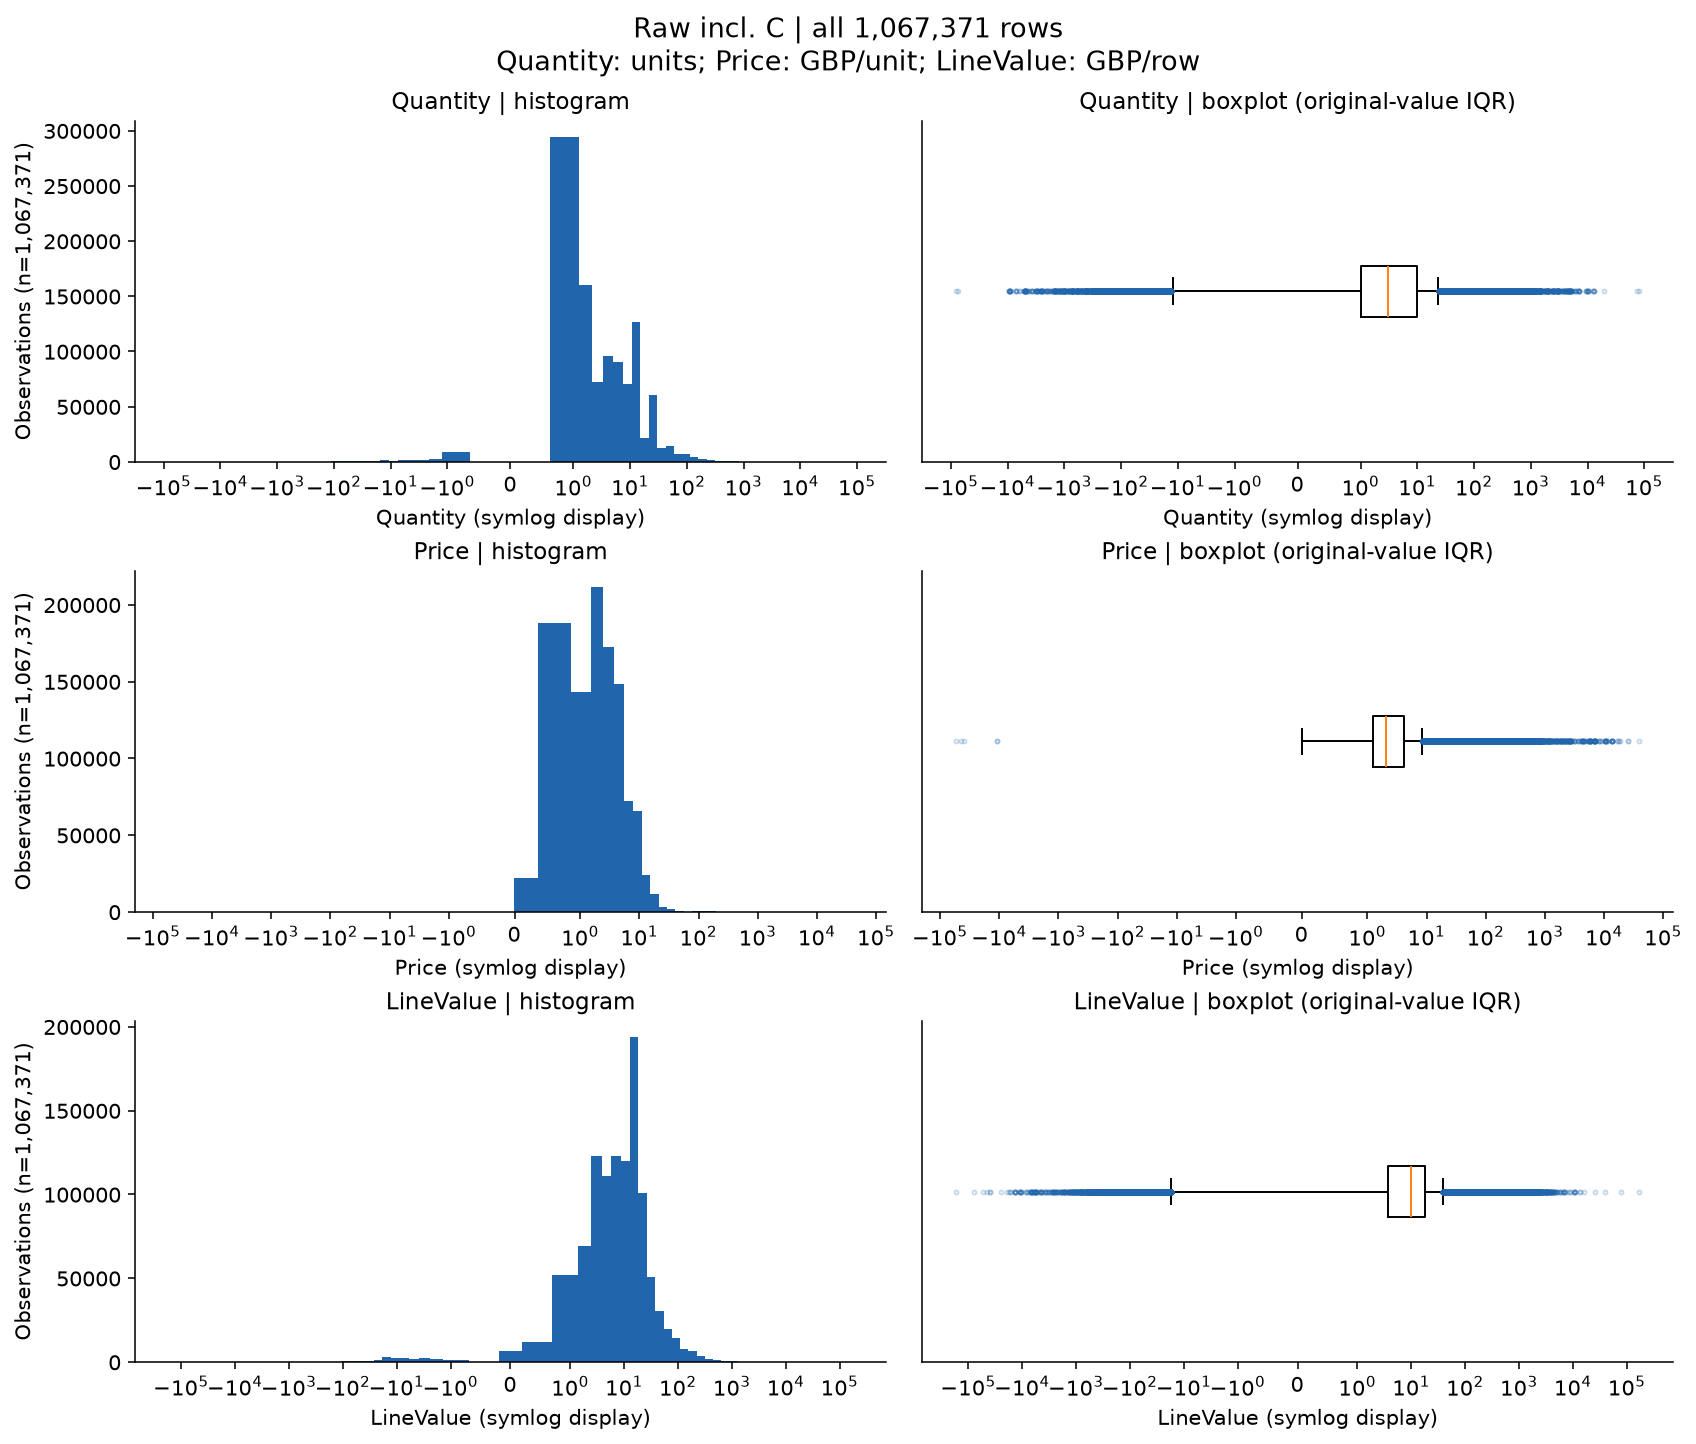

**Nhận xét:** Quantity: median=3.00, P99=100.00, min=-80,995.00, max=80,995.00, skew=4.00; Price: median=2.10, P99=18.00, min=-53,594.36, max=38,970.00, skew=-69.16; LineValue: median=9.90, P99=180.00, min=-168,469.60, max=168,469.60, skew=-12.44.

**Ý nghĩa đối với phân cụm:** Miền âm/dương và cực trị khiến mean đơn lẻ khó diễn giải; cần chọn góc nhìn mua trước log/scaling.

**Giới hạn / bước tiếp theo:** Histogram có bin symlog; boxplot giữ toàn miền symlog, ngưỡng IQR tính trên thang gốc. Skew có dấu của giá/giá trị thô chịu tác động cực trị âm; không tự gọi mọi biến là lệch phải. Không cắt dữ liệu.

In [4]:
show_figure(analysis, "raw_transaction_full_distributions")

**Câu hỏi:** Sau các bộ lọc hiện tại, đuôi phân phối còn lớn không?

**Dữ liệu và phạm vi:** 1,002,995 dòng đầu ra clean_data, gồm Guest; Q/P dương, đã lọc log-IQR k=3 của pipeline.

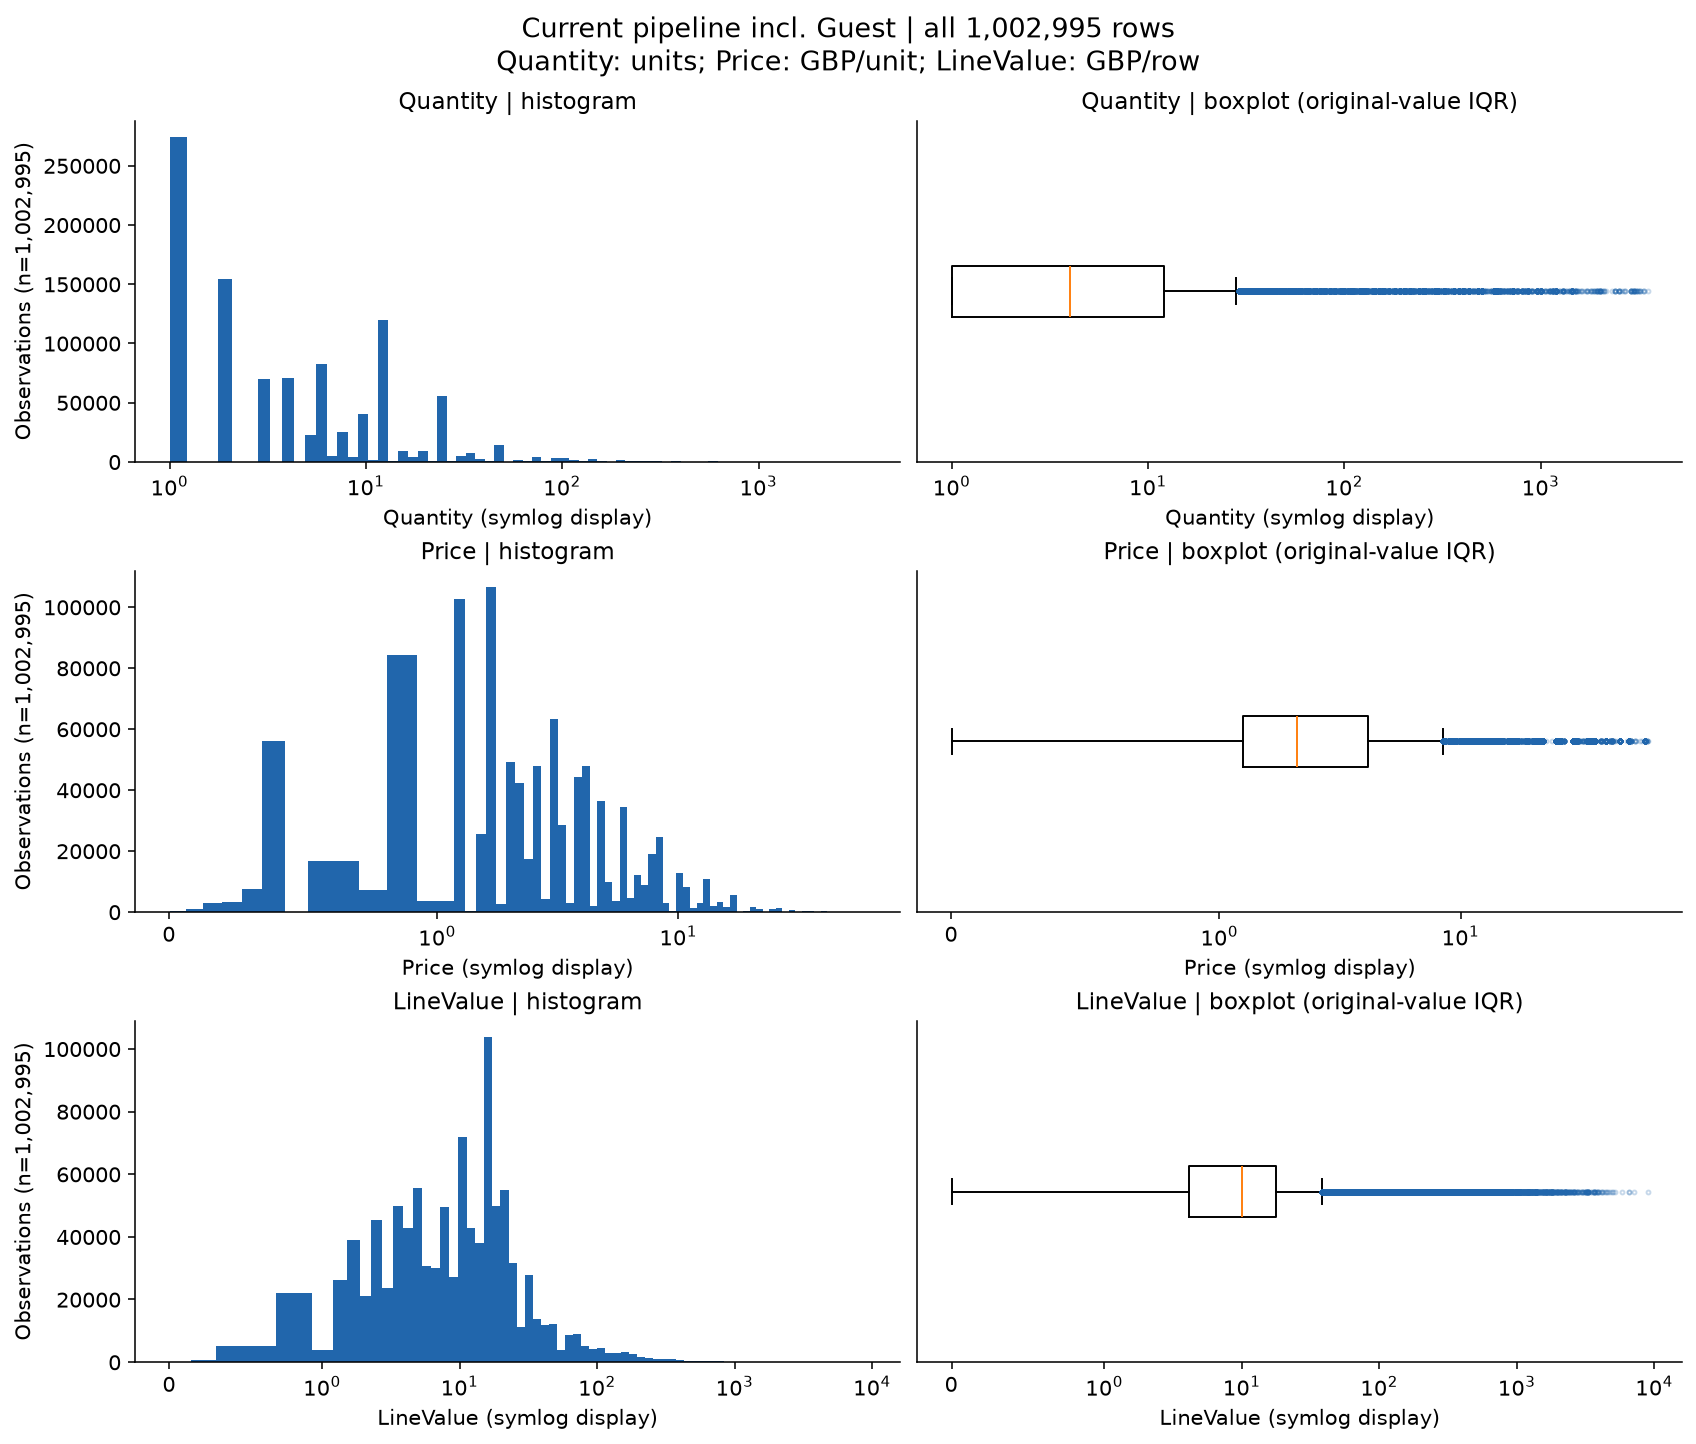

**Nhận xét:** Quantity: median=4.00, P99=106.00, max=3,500.00, ngoài IQR1.5=52,955; Price: median=2.10, P99=16.95, max=59.57, ngoài IQR1.5=74,757; LineValue: median=10.08, P99=179.00, max=8,925.00, ngoài IQR1.5=81,705.

**Ý nghĩa đối với phân cụm:** Lọc cực trị ở cấp dòng của pipeline chưa làm mất toàn bộ đuôi dài ở cấp khách; cần kiểm tra độ nhạy khi phân cụm.

**Giới hạn / bước tiếp theo:** EDA chỉ gắn cờ IQR1.5 trên thang gốc, không xóa thêm dòng/khách. Pipeline đã loại log-IQR k=3 là chính sách hiện có của Thuận; đề xuất giữ/xử lý khác cần nhóm xác nhận.

In [5]:
show_figure(analysis, "clean_transaction_full_distributions")

## 3. Mẫu cực trị cần kiểm tra

In [6]:
display(tables["extreme_rows"][["variable", "direction", "Invoice", "StockCode",
                              "Quantity", "Price", "LineValue", "InvoiceDate"]])


,variable,direction,Invoice,StockCode,Quantity,Price,LineValue,InvoiceDate
1065883,Quantity,smallest,C581484,23843,-80995,2.08,-168469.60,2011-12-09 09:27:00
587085,Quantity,smallest,C541433,23166,-74215,1.04,-77183.60,2011-01-18 10:17:00
179403,Price,smallest,A506401,B,1,-53594.36,-53594.36,2010-04-29 13:36:00
276274,Price,smallest,A516228,B,1,-44031.79,-44031.79,2010-07-19 11:24:00
1065883,LineValue,smallest,C581484,23843,-80995,2.08,-168469.60,2011-12-09 09:27:00
587085,LineValue,smallest,C541433,23166,-74215,1.04,-77183.60,2011-01-18 10:17:00
1065882,Quantity,largest,581483,23843,80995,2.08,168469.60,2011-12-09 09:15:00
587080,Quantity,largest,541431,23166,74215,1.04,77183.60,2011-01-18 10:01:00
748142,Price,largest,C556445,M,-1,38970.00,-38970.00,2011-06-10 15:31:00
241824,Price,largest,C512770,M,-1,25111.09,-25111.09,2010-06-17 16:52:00


Các cặp mua/C đối dấu chỉ hỗ trợ điều tra, chưa xác minh hoàn trả.
Phân biệt: lỗi có bằng chứng (chưa xác minh trong lần này), giá trị đặc biệt do nghiệp vụ,
khách giá trị cao hợp lệ và điểm được IQR gắn cờ. Ngưỡng thống kê không tự phân loại bốn nhóm.
Pipeline sẵn có lọc log-IQR Quantity/Price k=3; EDA giữ nguyên chính sách ấy và không xóa thêm
khách theo IQR1.5. Cần Thuận/nhóm xác nhận chính sách ngoại lệ chính thức.


## 4. Ngoại lệ và thiếu ở cấp khách

In [7]:
show_tables(analysis, ['customer_profile', 'feature_missing'])

**customer_profile** — 9 dòng; đầy đủ ở `analysis['tables']['customer_profile']`.

,population,variable,count,missing,nonfinite,mean,median,minimum,maximum,q1,q3,iqr,p95,p99,skewness,iqr_lower,iqr_upper,outside_iqr,outside_iqr_pct
0,known_ID_current_policy_experimental,Recency,5849,0,0,200.394109,95.407639,0.465278,738.549306,25.467361,379.388889,353.921528,623.457222,726.347889,0.892528,-505.414931,910.271181,0,0.000000
1,known_ID_current_policy_experimental,Frequency,5849,0,0,6.248419,3.000000,1.000000,373.000000,1.000000,7.000000,6.000000,20.000000,46.000000,12.049266,-8.000000,16.000000,423,7.232005
2,known_ID_current_policy_experimental,Monetary,5849,0,0,2846.698121,851.880000,2.900000,580987.040000,335.520000,2232.490000,1896.970000,9035.554000,26295.099600,26.295066,-2509.935000,5077.945000,616,10.531715
3,known_ID_current_policy_experimental,avg_order_value,5849,0,0,359.661449,276.058571,2.900000,14844.766667,175.200000,409.268000,234.068000,857.858261,1747.402560,12.770034,-175.902000,760.370000,374,6.394255
4,known_ID_current_policy_experimental,avg_purchase_gap_days,4227,1622,0,103.312251,72.893056,0.000000,714.152083,39.163472,130.947569,91.784097,323.389583,487.195333,2.166458,-98.512674,268.623715,307,7.262834
5,known_ID_current_policy_experimental,observed_tenure_days,5849,0,0,473.989430,529.459722,0.488889,738.677083,311.494444,666.593750,355.099306,735.497083,738.424667,-0.616355,-221.154514,1199.242708,0,0.000000
6,known_ID_current_policy_experimental,n_stock_codes_candidate,5849,0,0,82.183279,45.000000,1.000000,2542.000000,19.000000,103.000000,84.000000,281.000000,503.040000,6.218628,-107.000000,229.000000,451,7.710720
7,known_ID_current_policy_experimental,total_quantity_candidate,5849,0,0,1703.247564,484.000000,1.000000,367066.000000,189.000000,1351.000000,1162.000000,5342.400000,16383.320000,24.687180,-1554.000000,3094.000000,600,10.258164
8,known_ID_current_policy_experimental,avg_quantity_per_order_candidate,5849,0,0,227.748926,155.000000,1.000000,37847.000000,92.166667,259.750000,167.583333,549.978022,1274.080000,42.549649,-159.208333,511.125000,356,6.086511


**feature_missing** — 5 dòng; đầy đủ ở `analysis['tables']['feature_missing']`.

,missing_customers
avg_purchase_gap_days,1622
n_distinct_products,5849
avg_quantity_per_order,5849
total_quantity,5849
return_rate,5849


**Câu hỏi:** Hành vi từng khách có phân phối lệch đến đâu?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

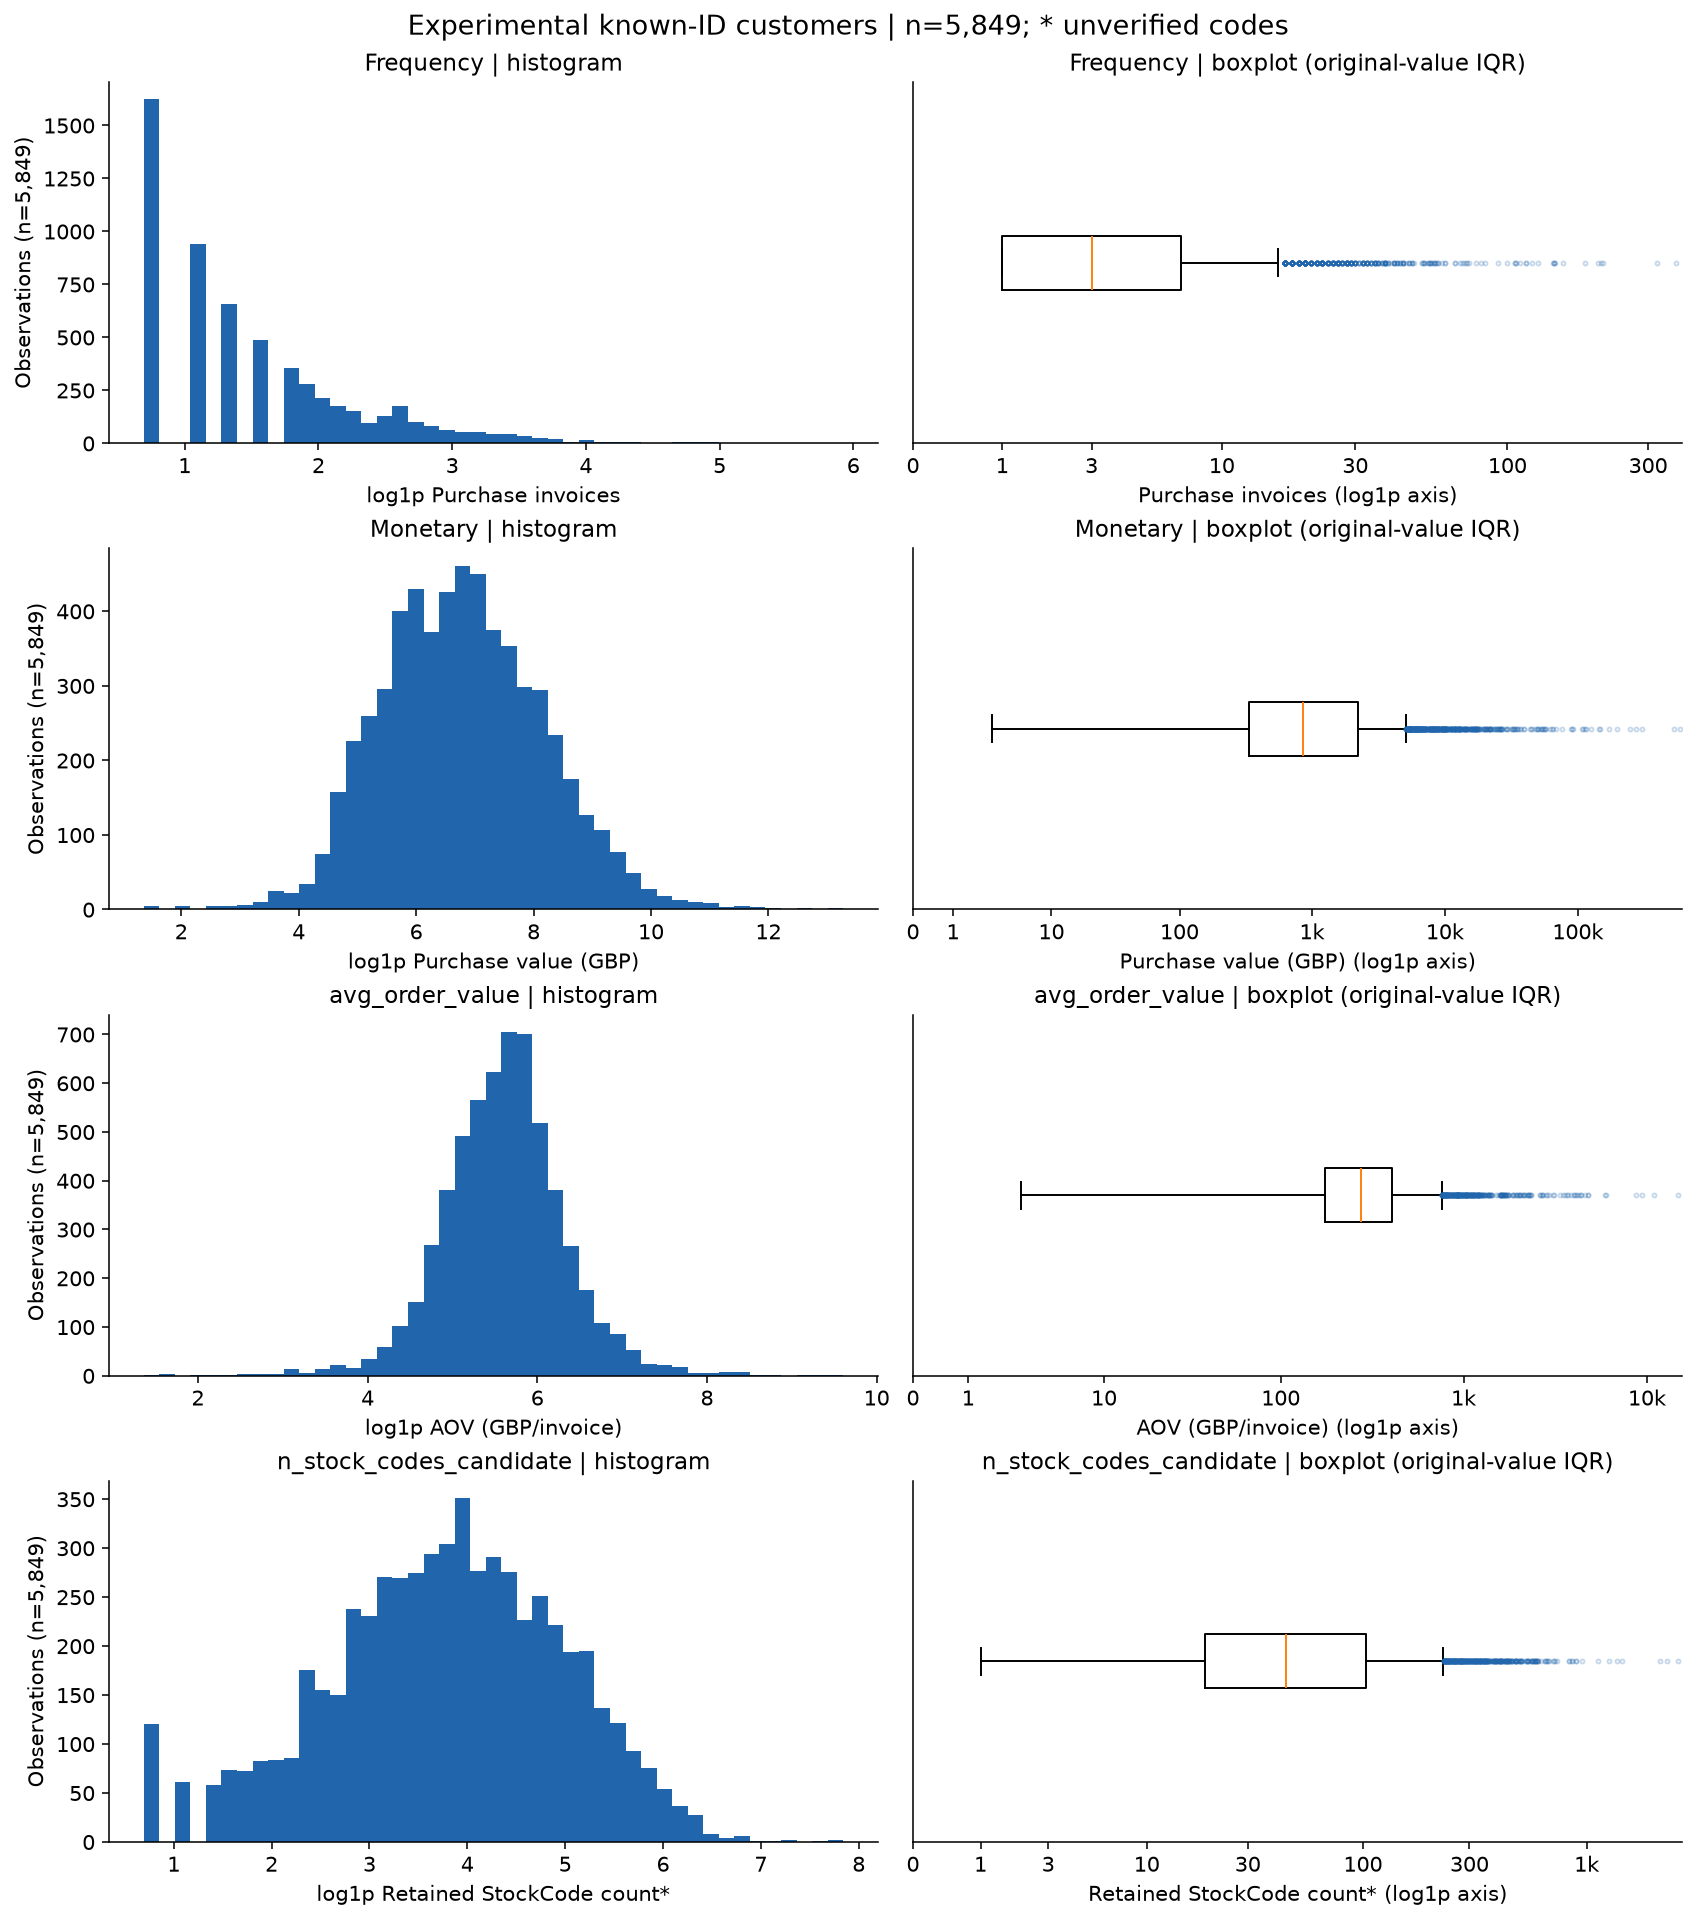

**Nhận xét:** Purchase invoices: median=3.00, P99=46.00, max=373.00, skew=12.05; Purchase value (GBP): median=851.88, P99=26,295.10, max=580,987.04, skew=26.30; AOV (GBP/invoice): median=276.06, P99=1,747.40, max=14,844.77, skew=12.77; Retained StockCode count*: median=45.00, P99=503.04, max=2,542.00, skew=6.22.

**Ý nghĩa đối với phân cụm:** Đuôi dài có thể chi phối khoảng cách Euclidean; khảo sát log1p/scaling và độ nhạy thay vì loại khách giá trị lớn.

**Giới hạn / bước tiếp theo:** Histogram và boxplot dùng thang log1p hiển thị, không xóa khách. * chỉ mã/đơn vị ứng viên; chưa xác minh danh mục sản phẩm.

In [8]:
show_figure(analysis, "customer_behavior_distributions")

**Câu hỏi:** Có bao nhiêu khách đủ lịch sử để tính khoảng cách mua?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

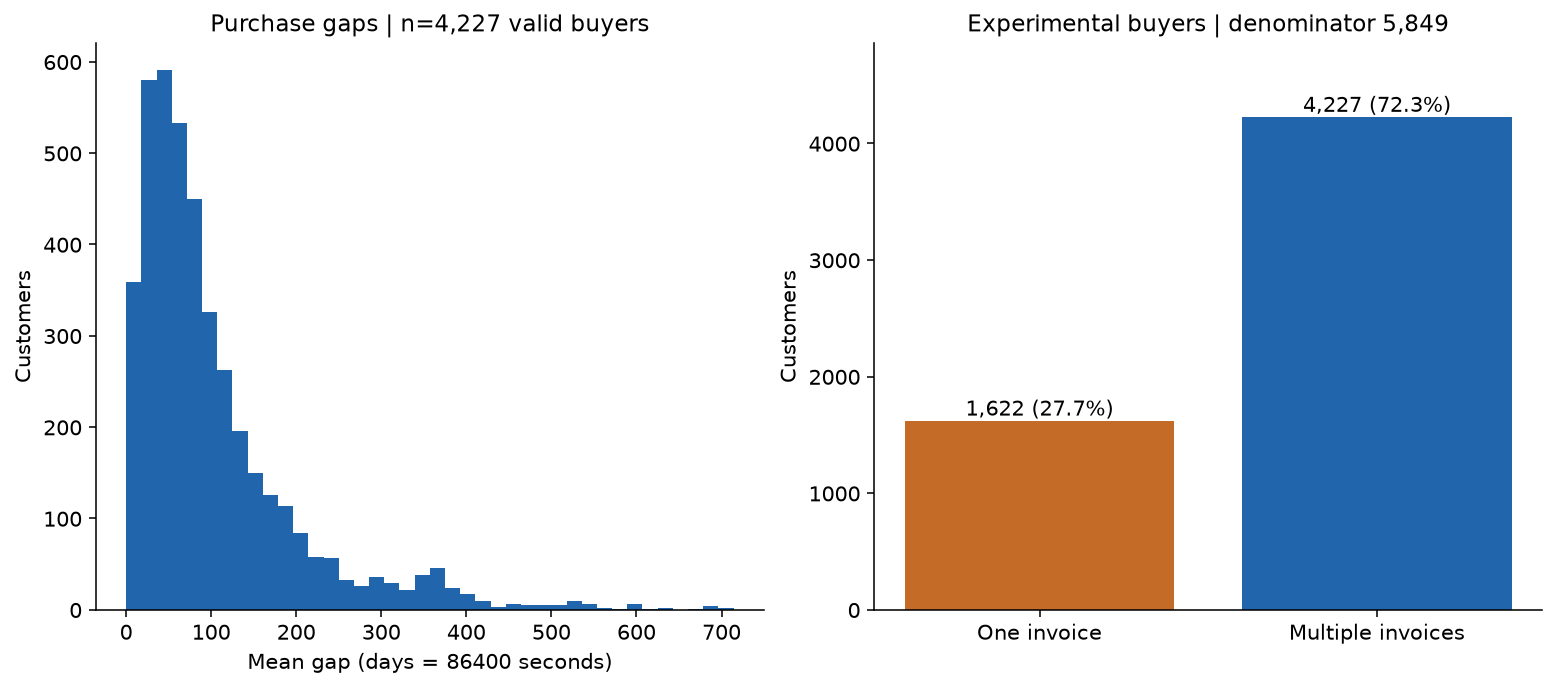

**Nhận xét:** 1,622/5,849 khách (27.73%) chỉ một Invoice; 4,227 khách còn lại có gap, trung vị 72.89 ngày. Gap nhỏ nhất 0.00 ngày.

**Ý nghĩa đối với phân cụm:** Gap thiếu có ý nghĩa cấu trúc; khi phân cụm cần chính sách thiếu/cờ một đơn, giữ 0 thật nếu các hóa đơn cùng thời điểm.

**Giới hạn / bước tiếp theo:** Không điền NaN bằng 0. Invoice nhiều thời điểm dùng earliest trong các dòng giữ lại; chưa biết lịch sử trước/sau cửa sổ.

In [9]:
show_figure(analysis, "customer_purchase_gaps")

## 5. RFM, log1p và scaling thử nghiệm

In [10]:
show_tables(analysis, ['scaling_parameters'])

**scaling_parameters** — 3 dòng; đầy đủ ở `analysis['tables']['scaling_parameters']`.

,feature,mean_log1p,variance_log1p,scale_log1p,fit_customers
0,Recency,4.448140,2.436945,1.561072,5849
1,Frequency,1.546410,0.652424,0.807728,5849
2,Monetary,6.797641,1.905713,1.380476,5849


**Câu hỏi:** R, F, M riêng lẻ có miền và độ lệch thế nào?

**Dữ liệu và phạm vi:** Thử nghiệm trên 5,849 khách có ID; một dòng/khách, sau clean_data hiện tại; cửa sổ [2009-12-01, 2011-12-10). Guest được loại khỏi khảo sát khách sau pipeline.

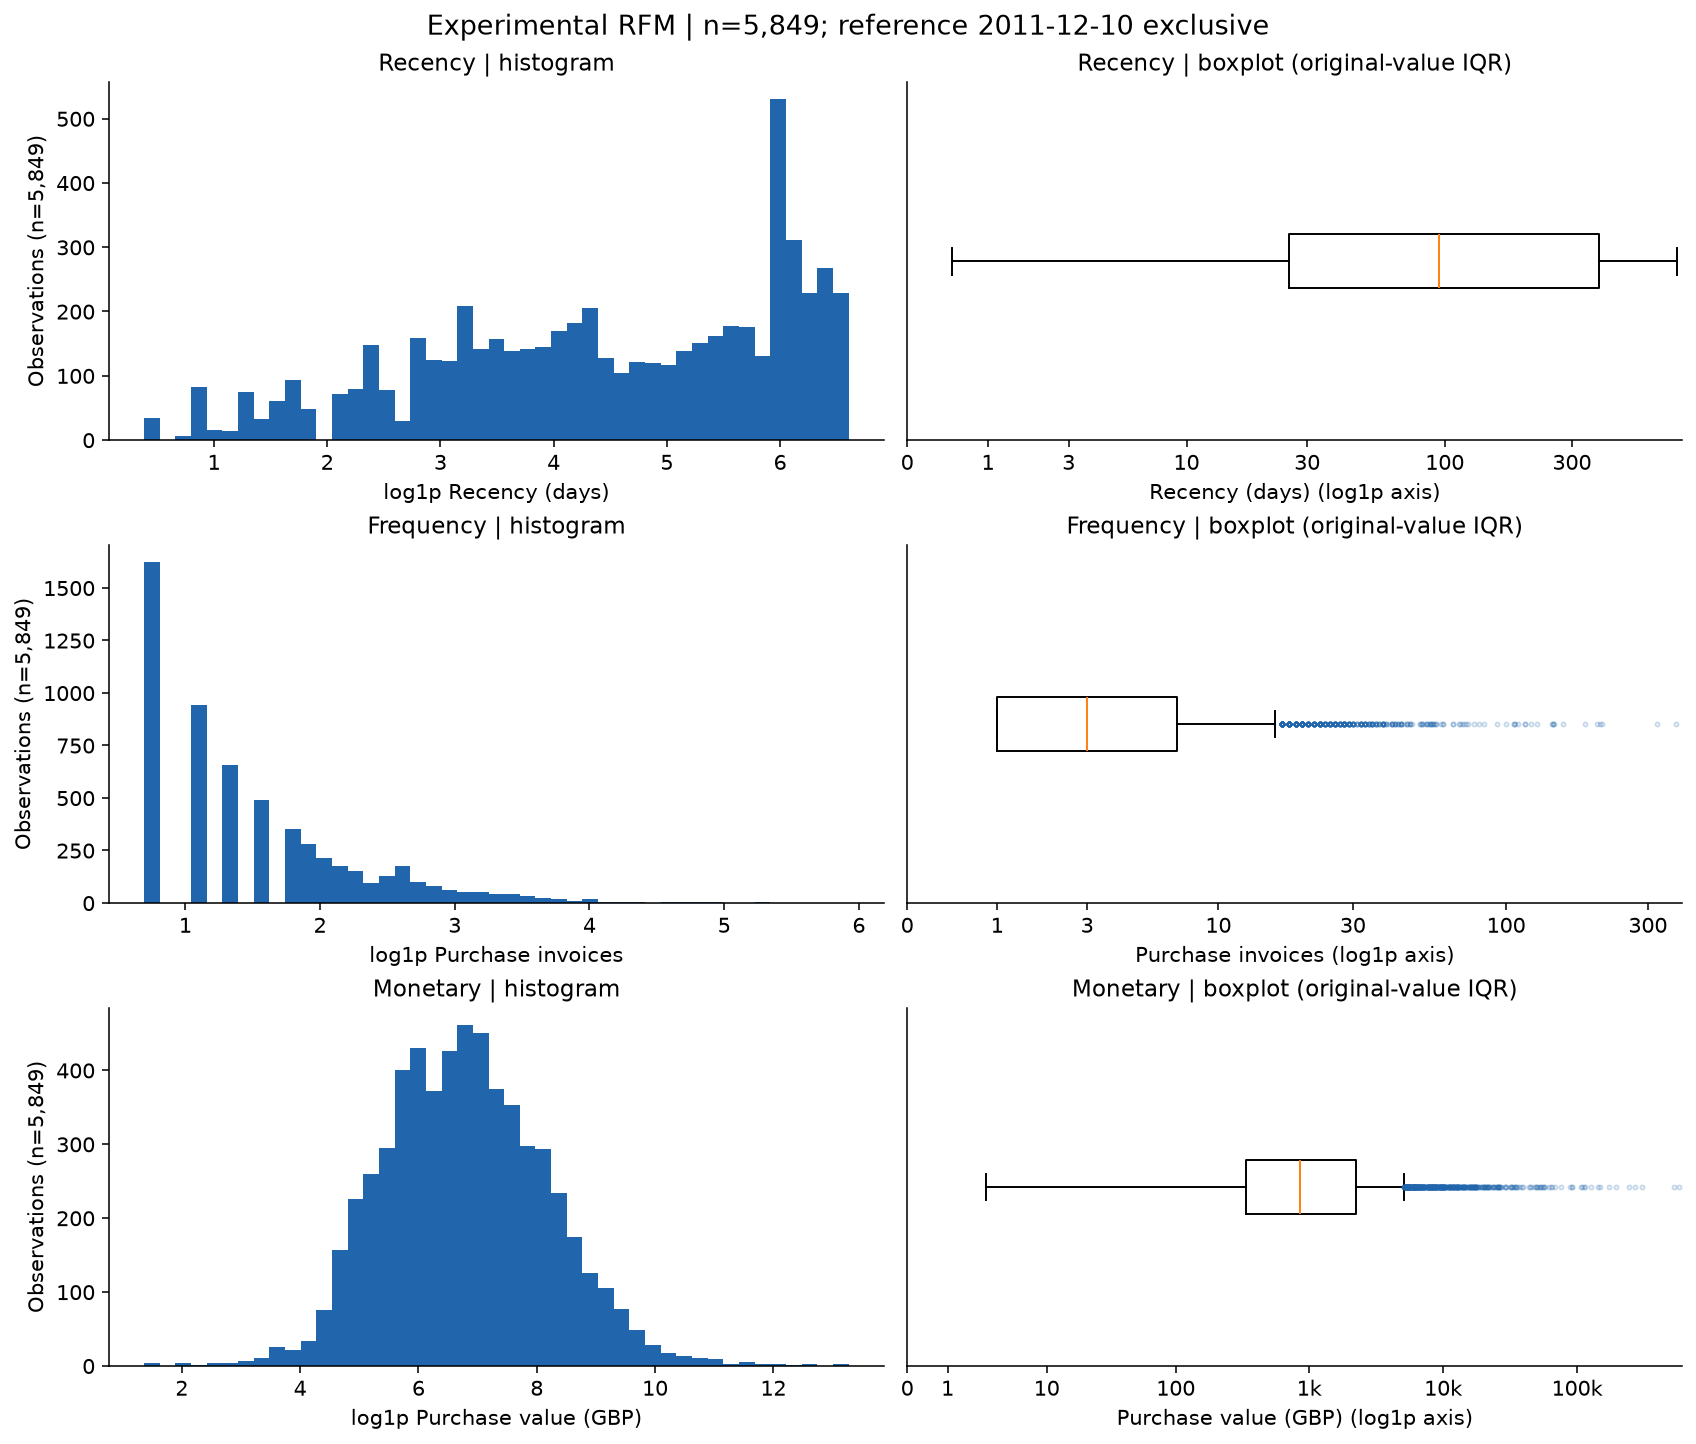

**Nhận xét:** Trung vị R=95.41 ngày; F=3 hóa đơn; M=851.88 GBP. R thiếu 0, F thiếu 0, M thiếu 0 khách; skew R/F/M=0.89/12.05/26.30.

**Ý nghĩa đối với phân cụm:** RFM thử nghiệm đủ dữ liệu cho khảo sát biến đổi; F/M có thang khác R nên cần cân nhắc trọng số và scaling.

**Giới hạn / bước tiếp theo:** R = reference − last invoice time; F = n_orders, M = total_purchase_value. Mốc tham chiếu 2011-12-10 loại trừ, không phải ngày hiện tại. Chưa chọn bộ biến mô hình chính thức.

In [11]:
show_figure(analysis, "rfm_experimental_distributions")

R = (2011-12-10 − thời điểm đơn cuối)/1 ngày; F = số Invoice, M = Σ Q×P chính xác.
Khách một đơn vẫn có R/F/M, nhưng gap thiếu. Mọi biến cùng cửa sổ [2009-12-01, 2011-12-10).
Fit StandardScaler (ddof=0) sau log1p R/F/M trên toàn bộ snapshot thử nghiệm;
chưa fit mô hình phân cụm hoặc lựa chọn bộ biến chính thức. Không có metric mô hình chưa chạy.
Tham số fit nằm trong bảng trên; công thức và mã tại eda_analysis.py.


## 6. Kiểm tra tái lập

In [12]:
print(validate_analysis(analysis))
with __import__("pandas").option_context("display.float_format", "{:.17g}".format):
    display(tables["scaling_parameters"])
display(analysis["metadata"] | {"protected_before": "SHA256 đã đối chiếu trước = sau"})


Đạt: khóa, công thức, tổng, khoảng cách, mọi cặp tương quan/n, scaling và checksum nguồn.


,feature,mean_log1p,variance_log1p,scale_log1p,fit_customers
0,Recency,4.4481400833254972,2.4369449131437166,1.5610717194106478,5849
1,Frequency,1.5464103991400771,0.65242434538896343,0.80772789068408646,5849
2,Monetary,6.7976414213201002,1.9057127364300201,1.3804755472046653,5849


{'run_at': '2026-11-05T08:31:54.277810+07:00',
 'client_date': '2026-11-05',
 'timezone': 'Asia/Bangkok',
 'git_head': 'df066eeca48f6b2aa11398f98f8e057db63a011d',
 'initial_scope': 'current clean_data, known-ID customers; unapproved business policy',
 'window_start': '2009-12-01',
 'reference_date_exclusive': '2011-12-10',
 'source_timestamp_timezone': 'unspecified; no timezone conversion',
 'python': '3.12.15',
 'versions': {'pandas': '3.1.0',
  'numpy': '2.5.4',
  'matplotlib': '3.11.2',
  'scipy': '1.18.1',
  'scikit-learn': '1.9.1',
  'openpyxl': '3.1.5',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'protected_before': 'SHA256 đã đối chiếu trước = sau',
 'eda_source_sha256': {'eda_analysis.py': '2bce1d46a36ae1920ecf3d08705f5f6b615c2f6fc26f66309cb27fd4b1d7989d',
  'eda_presentation.py': '09c0af21180a247b4044aa4f7e9e628bd6a29bf54ab711667bc4c16f87d33998',
  'eda_report.py': 'ea766fd6ef5d1097c5464e3b780985fd8696e8df40a4c06deebbaac8279c43d5'}}

Notebook này chỉ tái tạo 5 PNG chuyên sâu cùng tên và lưu output trong notebook,
không ghi CSV/báo cáo của v1. [Báo cáo EDA](../../reports/bao_cao_qua_trinh_eda.md)
và [hướng dẫn chạy](README.md) ghi giới hạn và các quyết định cần nhóm xác nhận.
Codex hỗ trợ tổ chức mã/diễn giải và rà soát kết quả; nhóm kiểm tra nội dung trước khi nộp.
